In [ ]:
print("testing")

testing


Cell 1: setup

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:                                        # Colab
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/retail-project")
except ImportError:                         # local (notebook is in notebooks/)
    BASE = Path("..")

PROCESSED = BASE / "data/processed"
REPORTS = BASE / "reports"
FIGURES = REPORTS / "figures"
TABLES = REPORTS / "tables"
for p in (FIGURES, TABLES):
    p.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cell 2: load data

In [ ]:
dtypes = {"invoice": str, "stock_code": str}
sales = pd.read_csv(PROCESSED / "sales_clean.csv", dtype=dtypes, parse_dates=["invoice_date"])
returns = pd.read_csv(PROCESSED / "returns_clean.csv", dtype=dtypes, parse_dates=["invoice_date"])
for d in (sales, returns):
    d["customer_id"] = d["customer_id"].astype("Int64")

lines = pd.concat([sales, returns])          # returns are negative, so this nets them
print(len(sales), len(returns), f"{lines['revenue'].sum():,.0f}")   # expect 18,927,436

1003340 17914 18,927,436


Cell 3: Q1, tren penjualan (year 1 vs year 2)

Year 1: 9,156,118 | Year 2: 9,330,918 | change: +1.9%


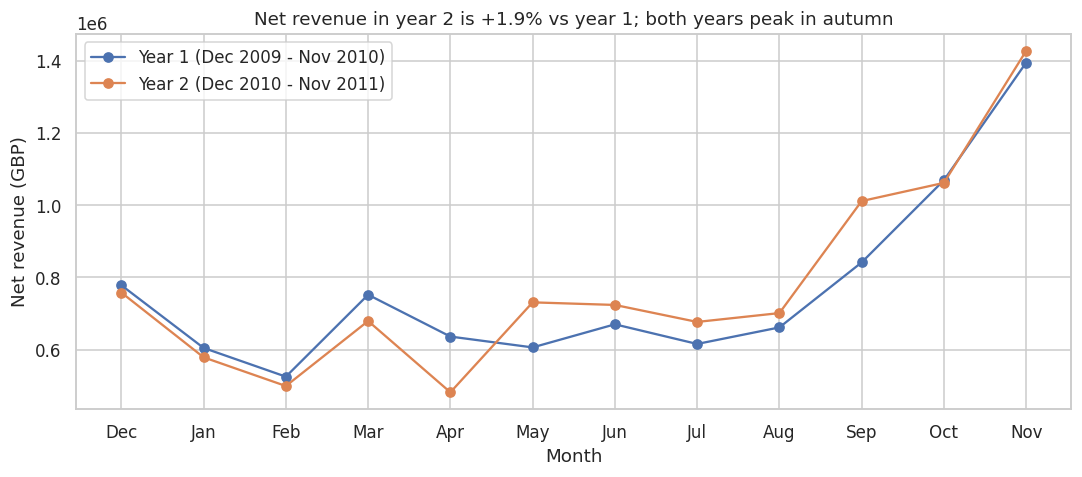

In [ ]:
lines["month"] = lines["invoice_date"].dt.to_period("M").dt.to_timestamp()
monthly = lines.groupby("month")["revenue"].sum().round()
full = monthly[monthly.index < "2011-12-01"]        # Dec 2011 is incomplete

y1 = full[full.index < "2010-12-01"].sum()
y2 = full[full.index >= "2010-12-01"].sum()
chg = (y2 / y1 - 1) * 100
print(f"Year 1: {y1:,.0f} | Year 2: {y2:,.0f} | change: {chg:+.1f}%")

t = full.reset_index()
t["year"] = np.where(t["month"] < "2010-12-01", "Year 1 (Dec 2009 - Nov 2010)", "Year 2 (Dec 2010 - Nov 2011)")
t["m"] = t["month"].dt.month % 12 + 1               # Dec = 1, Jan = 2, ... Nov = 12
pivot = t.pivot(index="m", columns="year", values="revenue")

fig, ax = plt.subplots(figsize=(10, 4.5))
pivot.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"])
ax.set_title(f"Net revenue in year 2 is {chg:+.1f}% vs year 1; both years peak in autumn")
ax.set_xlabel("Month"); ax.set_ylabel("Net revenue (GBP)"); ax.legend(title="")
plt.tight_layout(); plt.savefig(FIGURES / "01_monthly_trend.png"); plt.show()

Cell 4: Q2, produk

4894 products | top 10% (489) = 62% of sales | bottom 20% = 0.3% of sales


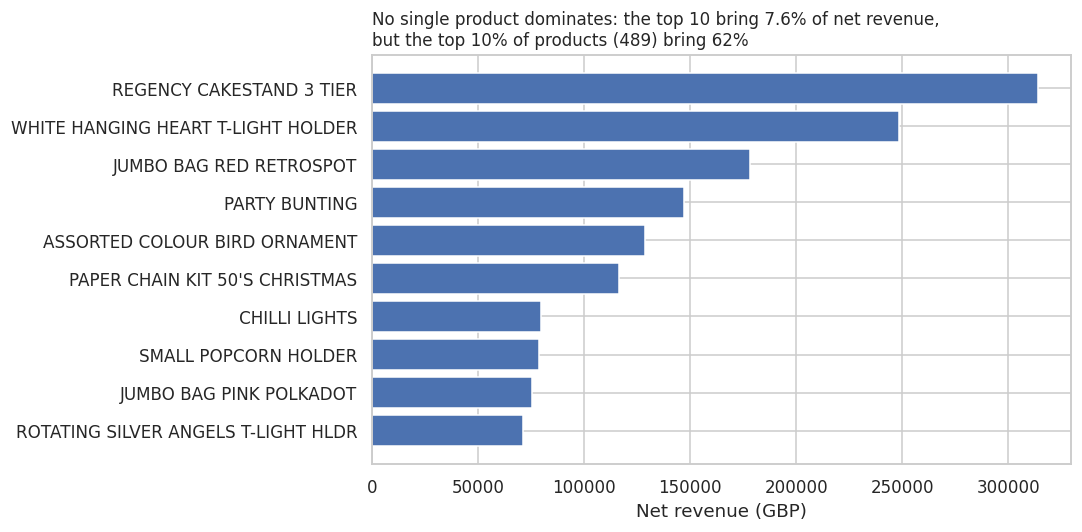

In [ ]:
prod = (lines.groupby(["stock_code", "description"])["revenue"].sum()
             .sort_values(ascending=False).reset_index())
prod["share"] = prod["revenue"] / prod["revenue"].sum()
prod["cum_share"] = prod["share"].cumsum()

n = len(prod)
k = int(n * 0.1)
top_share = prod.head(k)["share"].sum() * 100
bottom_share = prod.tail(int(n * 0.2))["share"].sum() * 100
print(f"{n} products | top 10% ({k}) = {top_share:.0f}% of sales | bottom 20% = {bottom_share:.1f}% of sales")

top10_share = prod.head(10)["share"].sum() * 100
top10 = prod.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10["description"], top10["revenue"])
ax.set_title(f"No single product dominates: the top 10 bring {top10_share:.1f}% of net revenue,\n"
             f"but the top 10% of products ({k}) bring {top_share:.0f}%", loc="left", fontsize=11)
ax.set_xlabel("Net revenue (GBP)")
plt.tight_layout(); plt.savefig(FIGURES / "02_top_products.png"); plt.show()

Cell 5: Q4, negara

                    revenue  customers  orders  share      aov
country                                                       
United Kingdom  16168942.53       5334   36184   0.85   446.85
EIRE              603116.61          3     581   0.03  1038.07
Netherlands       546095.43         22     216   0.03  2528.22
Germany           374573.51        107     753   0.02   497.44
France            293431.20         93     598   0.02   490.69
Australia         166282.15         15      89   0.01  1868.34
Switzerland        92918.06         22      85   0.00  1093.15
Spain              84811.56         38     144   0.00   588.97
Sweden             84345.17         19      99   0.00   851.97
Denmark            63355.59         12      42   0.00  1508.47


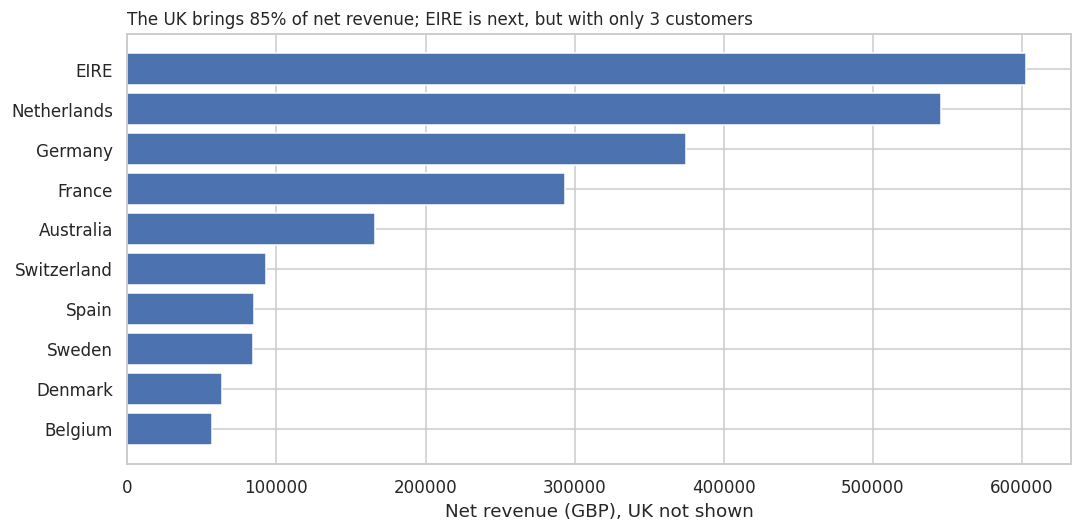

In [ ]:
ctry = lines.groupby("country")["revenue"].sum().to_frame("revenue")
ctry["customers"] = sales.groupby("country")["customer_id"].nunique()
ctry["orders"] = sales.groupby("country")["invoice"].nunique()
ctry = ctry.sort_values("revenue", ascending=False)
ctry["share"] = ctry["revenue"] / ctry["revenue"].sum()
ctry["aov"] = ctry["revenue"] / ctry["orders"]

uk = ctry.loc["United Kingdom", "share"] * 100
others = ctry.drop("United Kingdom").head(10).iloc[::-1]
print(ctry.head(10).round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(others.index, others["revenue"])
top_c = others.index[-1]
ax.set_title(f"The UK brings {uk:.0f}% of net revenue; {top_c} is next, but with only "
             f"{int(others.loc[top_c, 'customers'])} customers", loc="left", fontsize=11)
ax.set_xlabel("Net revenue (GBP), UK not shown")
plt.tight_layout(); plt.savefig(FIGURES / "03_countries.png"); plt.show()

Cell 6: RFM (pelanggan terbaik)

                      customers     revenue  pct_customers  pct_revenue
segment                                                                
Champions                  1469  11494395.3           25.1         70.3
Loyal                       872   2612360.3           14.9         16.0
Recent or occasional       1531   1207749.5           26.2          7.4
Lost                       1510    605264.4           25.8          3.7
At risk                     470    440266.0            8.0          2.7


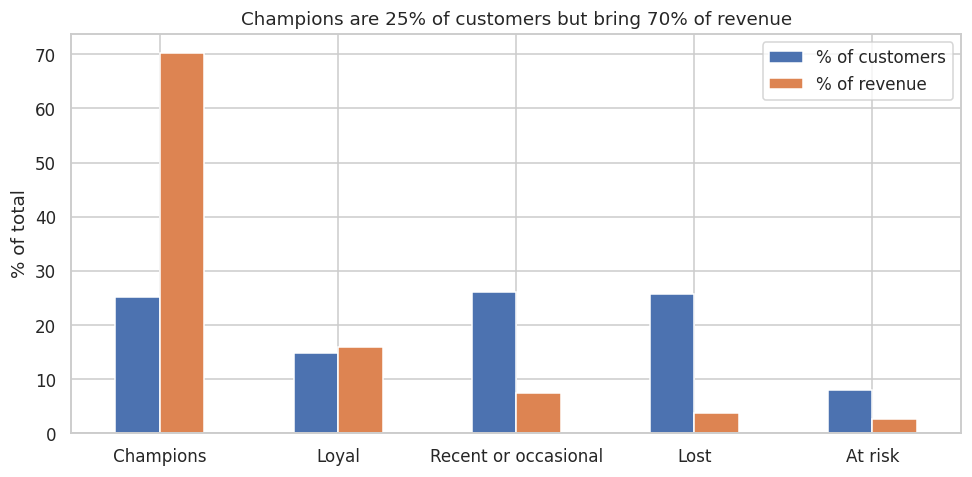

In [ ]:
cust = sales.dropna(subset=["customer_id"]).copy()
snapshot = cust["invoice_date"].max().normalize() + pd.Timedelta(days=1)

rfm = cust.groupby("customer_id").agg(
    recency=("invoice_date", lambda s: (snapshot - s.max()).days),
    frequency=("invoice", "nunique"),
)
rfm["monetary"] = lines.dropna(subset=["customer_id"]).groupby("customer_id")["revenue"].sum()

rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

conditions = [
    (rfm["R"] >= 4) & (rfm["F"] >= 4),
    (rfm["F"] >= 4),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2),
]
names = ["Champions", "Loyal", "At risk", "Lost"]
rfm["segment"] = np.select(conditions, names, default="Recent or occasional")

seg = rfm.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"))
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_revenue"] = seg["revenue"] / seg["revenue"].sum() * 100
seg = seg.sort_values("pct_revenue", ascending=False)
print(seg.round(1))

ch = seg.loc["Champions"]
fig, ax = plt.subplots(figsize=(9, 4.5))
seg[["pct_customers", "pct_revenue"]].plot.bar(ax=ax)
ax.set_title(f"Champions are {ch['pct_customers']:.0f}% of customers but bring {ch['pct_revenue']:.0f}% of revenue")
ax.set_ylabel("% of total"); ax.set_xlabel("")
ax.legend(["% of customers", "% of revenue"])
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIGURES / "04_rfm_segments.png"); plt.show()

Cell 7: retensi (apakah pelanggan kembali)

Repeat rate: 72% | average share still buying 3 months after first order: 21%


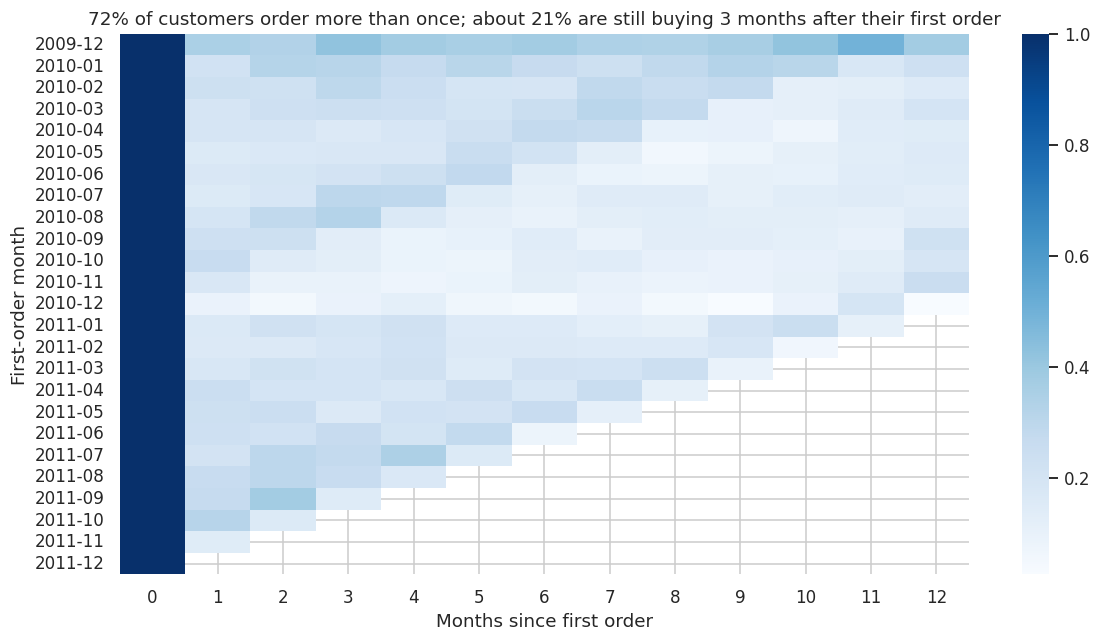

In [ ]:
cust["order_month"] = cust["invoice_date"].dt.to_period("M")
cust["cohort"] = cust.groupby("customer_id")["invoice_date"].transform("min").dt.to_period("M")
cust["age"] = (cust["order_month"] - cust["cohort"]).apply(lambda x: x.n)

cohort = cust.groupby(["cohort", "age"])["customer_id"].nunique().unstack()
retention = cohort.div(cohort[0], axis=0)

repeat_rate = (rfm["frequency"] >= 2).mean() * 100
m3 = retention.loc["2010-01":, 3].mean() * 100          # skip Dec 2009: includes existing customers
print(f"Repeat rate: {repeat_rate:.0f}% | average share still buying 3 months after first order: {m3:.0f}%")

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(retention.iloc[:, :13], cmap="Blues", fmt=".0%", annot=False,
            yticklabels=retention.index.astype(str), ax=ax)
ax.set_title(f"{repeat_rate:.0f}% of customers order more than once; about {m3:.0f}% are still buying 3 months after their first order")
ax.set_xlabel("Months since first order"); ax.set_ylabel("First-order month")
plt.tight_layout(); plt.savefig(FIGURES / "05_retention.png"); plt.show()

Cell 8: simpan tabel untuk Excel dan dashboard

In [ ]:
full.rename("net_revenue").to_csv(TABLES / "monthly_net_revenue.csv")
prod.head(50).to_csv(TABLES / "top_products.csv", index=False)
ctry.round(2).to_csv(TABLES / "countries.csv")
seg.round(1).to_csv(TABLES / "rfm_segments.csv")
rfm.to_csv(TABLES / "rfm_customers.csv")
retention.round(3).to_csv(TABLES / "retention_cohorts.csv")

In [ ]:
out = lines[["invoice", "invoice_date", "stock_code", "description",
             "country", "customer_id", "quantity", "revenue"]].copy()
out["type"] = np.where(out["invoice"].str.startswith("C"), "Return", "Sale")
out["month"] = out["invoice_date"].dt.to_period("M").dt.to_timestamp().dt.date
out["period"] = np.select(
    [out["invoice_date"] < "2010-12-01", out["invoice_date"] < "2011-12-01"],
    ["Year 1 (Dec 2009 - Nov 2010)", "Year 2 (Dec 2010 - Nov 2011)"],
    default="Dec 2011 (partial)")
out["segment"] = out["customer_id"].map(rfm["segment"]).astype(object).fillna("No customer ID")
out["revenue"] = out["revenue"].round(2)

out.to_csv(PROCESSED / "dashboard_lines.csv", index=False)
print(len(out), f"{out['revenue'].sum():,.0f}")
print("orders:", sales["invoice"].nunique(), "| customers:", sales["customer_id"].nunique())

1021254 18,927,436
orders: 39516 | customers: 5852


In [ ]:
s = out[out["type"] == "Sale"]
print("customers in csv:", s["customer_id"].nunique(), "| in rfm:", len(rfm))
print("min/max:", s["customer_id"].min(), s["customer_id"].max())
print("not in rfm:", set(s["customer_id"].dropna()) - set(rfm.index))

customers in csv: 5852 | in rfm: 5852
min/max: 12346 18287
not in rfm: set()
